# 04b — ConvNeXt-Tiny  (v2 data: field photos + "Other" class + leak-free split)

All four model notebooks use the **same manifest/split**, the **same augmentation, loss, label smoothing and early-stopping rule**, and the **same evaluation**, so the comparison is fair.

What this notebook reports (saved to Drive as `results/convnext_tiny_metrics.json`):
1. In-domain test accuracy / macro-F1 (leak-free PlantVillage split)
2. **Field test** (PlantDoc leaf crops) and **scene test** (PlantDoc whole photos, like a user upload), never trained on
3. Calibration (ECE before/after temperature scaling)
4. **Unknown-image detection** on `ood_test` (apple/tomato leaves, pets, other field crops): AUROC, FPR@95, and the real deployment rule
5. Robustness (dark, bright, blur, JPEG, rotate, crop, noise, low-res)
6. Size and latency (GPU + CPU)

Modern CNN (28M params, ImageNet-12k pre-trained). Between the small CNNs and the ViTs: strong transfer learning and good robustness; ~3-4x slower to train than EfficientNet-B0 on a T4.

In [1]:
from google.colab import drive
drive.mount("/content/drive")
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm", "scikit-learn", "scipy"], check=True)

import os, json, time, math, random, zipfile
from io import BytesIO
from pathlib import Path
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import timm
from PIL import Image, ImageEnhance, ImageFilter
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from scipy.special import logsumexp
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, confusion_matrix, classification_report)
import matplotlib; import matplotlib.pyplot as plt

SEED = 42
def seed_all(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all()
assert torch.cuda.is_available(), "Switch Runtime -> Change runtime type -> T4 GPU"
device = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0), "| torch", torch.__version__, "| timm", timm.__version__)

DRIVE_ROOT = Path("/content/drive/MyDrive/plant-disease-v2")
CKPT_DIR = DRIVE_ROOT / "checkpoints"; RES_DIR = DRIVE_ROOT / "results"
CKPT_DIR.mkdir(parents=True, exist_ok=True); RES_DIR.mkdir(parents=True, exist_ok=True)

import hashlib, shutil
DATA = Path("/content/data_v2")
zp = DRIVE_ROOT / "data_v2.zip"
assert zp.exists(), "Run notebook 00 first (data_v2.zip not found on Drive)."
with zipfile.ZipFile(zp) as z: MANIFEST_MD5 = hashlib.md5(z.read("manifest.csv")).hexdigest()
have_md5 = hashlib.md5(open(DATA / "manifest.csv", "rb").read()).hexdigest() if (DATA / "manifest.csv").exists() else None
if have_md5 != MANIFEST_MD5:      # missing, or a stale copy of an older dataset build -> extract the current one
    shutil.rmtree(DATA, ignore_errors=True); t0 = time.time()
    with zipfile.ZipFile(zp) as z: z.extractall(DATA)
    print(f"unzipped in {time.time() - t0:.0f}s")
print("dataset manifest md5:", MANIFEST_MD5, "(must be identical in all model notebooks)")


Mounted at /content/drive
GPU: Tesla T4 | torch 2.11.0+cu130 | timm 1.0.30
unzipped in 13s
dataset manifest md5: c0c74aae5361191f93208dcd44c3a7f4 (must be identical in all model notebooks)


In [2]:
# ============ CONFIG (the only per-model part) ============
SHORT       = "convnext_tiny"
TIMM_NAME   = "convnext_tiny"
MODEL_KW    = dict(drop_path_rate=0.1)            # extra timm.create_model kwargs
LR          = 1e-4            # backbone learning rate
HEAD_MULT   = 5      # classifier LR = LR * HEAD_MULT
WEIGHT_DECAY= 5e-2
BATCH       = 32
EPOCHS      = 12
PATIENCE    = 5                 # early stopping on val macro-F1
LABEL_SMOOTH= 0.1
IMG = 224
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

meta = json.load(open(DATA / "meta.json"))
CLASS_NAMES = meta["class_names"]; NUM_CLASSES = len(CLASS_NAMES); OTHER_IDX = meta["other_index"]
df = pd.read_csv(DATA / "manifest.csv")
assert NUM_CLASSES == 11 and CLASS_NAMES[-1] == "Other_or_not_leaf" and OTHER_IDX == NUM_CLASSES - 1, "unexpected class list / order: rebuild the dataset with notebook 00"
assert (df.y == df.label.map({c_: i_ for i_, c_ in enumerate(CLASS_NAMES)})).all(), "manifest labels and class order disagree"
print(pd.crosstab(df.label, df.split))

split                                               field_test  ood_test  \
label                                                                      
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot           4         0   
Corn_(maize)___Common_rust_                                 10         0   
Corn_(maize)___Northern_Leaf_Blight                         11         0   
Corn_(maize)___healthy                                       0         0   
Grape___Black_rot                                            8         0   
Grape___Esca_(Black_Measles)                                 0         0   
Grape___Leaf_blight_(Isariopsis_Leaf_Spot)                   0         0   
Grape___healthy                                             15         0   
Other_or_not_leaf                                            0      2324   
Pepper,_bell___Bacterial_spot                               15         0   
Pepper,_bell___healthy                                      11         0   

split      

In [3]:
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG, scale=(0.4, 1.0), ratio=(0.75, 1.33)),
    transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(0.3),
    transforms.RandomRotation(25),
    transforms.ColorJitter(0.35, 0.35, 0.3, 0.05),
    transforms.RandomApply([transforms.GaussianBlur(5, (0.1, 2.0))], p=0.3),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD),
    transforms.RandomErasing(p=0.25, scale=(0.02, 0.15)),
])
eval_tf = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(IMG),
                              transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

def perturb(img, c):
    if c == "dark":   return ImageEnhance.Brightness(img).enhance(0.6)
    if c == "bright": return ImageEnhance.Brightness(img).enhance(1.3)
    if c == "blur":   return img.filter(ImageFilter.GaussianBlur(1.5))
    if c == "jpeg":
        b = BytesIO(); img.save(b, "JPEG", quality=30); b.seek(0); return Image.open(b).convert("RGB")
    if c == "rotate": return img.rotate(20, resample=Image.BILINEAR)
    if c == "crop":
        w, h = img.size; return img.crop((int(.1 * w), int(.1 * h), int(.9 * w), int(.9 * h)))
    if c == "noise":
        a = np.asarray(img).astype(np.float32) + np.random.normal(0, 12, (img.size[1], img.size[0], 3))
        return Image.fromarray(a.clip(0, 255).astype(np.uint8))
    if c == "lowres":
        w, h = img.size; return img.resize((max(32, w // 3), max(32, h // 3))).resize((w, h))
    return img

class DS(Dataset):
    def __init__(self, d, tf, cond="clean"):
        self.p = [DATA / p for p in d.path]; self.y = d.y.values; self.tf = tf; self.cond = cond
    def __len__(self): return len(self.p)
    def __getitem__(self, i):
        img = Image.open(self.p[i]).convert("RGB")
        if self.cond != "clean": img = perturb(img, self.cond)
        return self.tf(img), int(self.y[i])

def loader(d, tf, shuffle=False, bs=64, cond="clean"):
    return DataLoader(DS(d, tf, cond), batch_size=bs, shuffle=shuffle, num_workers=2, pin_memory=True,
                      drop_last=shuffle, persistent_workers=False)

D = {s: df[df.split == s].reset_index(drop=True) for s in ["train", "val", "test", "field_test", "scene_test", "ood_test"]}
train_loader = loader(D["train"], train_tf, shuffle=True, bs=BATCH)
val_loader   = loader(D["val"], eval_tf)
test_loader  = loader(D["test"], eval_tf)
field_loader = loader(D["field_test"], eval_tf)
ood_loader   = loader(D["ood_test"], eval_tf)
assert len(D["field_test"]) > 0, "no PlantDoc field images - re-run notebook 00"
HAS_SCENE = len(D["scene_test"]) > 0
scene_loader = loader(D["scene_test"], eval_tf) if HAS_SCENE else None
train_eval_loader = loader(D["train"][D["train"].y < OTHER_IDX].reset_index(drop=True), eval_tf)   # for Mahalanobis fit
print({k: len(v) for k, v in D.items()})

counts = np.bincount(D["train"].y.values, minlength=NUM_CLASSES)
assert (counts > 0).all(), f"a class has NO training images - the split is broken, rebuild with notebook 00: {counts}"
class_w = torch.tensor(len(D["train"]) / (NUM_CLASSES * counts), dtype=torch.float32)
print("class weights:", class_w.numpy().round(2))

{'train': 17253, 'val': 2041, 'test': 1410, 'field_test': 74, 'scene_test': 43, 'ood_test': 2324}
class weights: [2.96 1.36 1.25 1.68 1.43 1.41 1.82 2.85 1.5  1.02 0.22]


In [4]:
seed_all()
model = timm.create_model(TIMM_NAME, pretrained=True, num_classes=NUM_CLASSES, **MODEL_KW).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"{TIMM_NAME}: {n_params / 1e6:.2f} M parameters | feature dim {model.num_features}")

head_ids = {id(p) for p in model.get_classifier().parameters()}
head = [p for p in model.parameters() if id(p) in head_ids]
body = [p for p in model.parameters() if id(p) not in head_ids]
opt = torch.optim.AdamW([{"params": body, "lr": LR}, {"params": head, "lr": LR * HEAD_MULT}],
                        weight_decay=WEIGHT_DECAY)
total = EPOCHS * len(train_loader); warm = len(train_loader)
lam = lambda s: (s + 1) / warm if s < warm else 0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm)))
sched = torch.optim.lr_scheduler.LambdaLR(opt, lam)
crit = nn.CrossEntropyLoss(weight=class_w.to(device), label_smoothing=LABEL_SMOOTH)
scaler = torch.amp.GradScaler("cuda")

@torch.inference_mode()
def run(m, ld):
    """returns logits, penultimate features, labels (eval mode, fp16 autocast)"""
    m.eval(); L, Fe, Y = [], [], []
    for x, y in ld:
        x = x.to(device, non_blocking=True)
        with torch.autocast("cuda", dtype=torch.float16):
            f = m.forward_head(m.forward_features(x), pre_logits=True)
            lg = m.get_classifier()(f)
        Fe.append(f.float().cpu()); L.append(lg.float().cpu()); Y.append(y)
    return torch.cat(L).numpy(), torch.cat(Fe).numpy(), torch.cat(Y).numpy()

def quick_eval(ld):
    lg, _, y = run(model, ld); p = lg.argmax(1)
    return dict(loss=F.cross_entropy(torch.tensor(lg), torch.tensor(y)).item(),
                acc=accuracy_score(y, p), f1=f1_score(y, p, average="macro", zero_division=0))

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

convnext_tiny: 27.83 M parameters | feature dim 768


/tmp/ipykernel_590/1616255015.py:13: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step()


ep 01/12   206s | train loss 1.175 acc 0.7676 | val loss 0.549 acc 0.8961 F1 0.8953 * BEST
ep 02/12   183s | train loss 0.937 acc 0.8941 | val loss 0.413 acc 0.9388 F1 0.9239 * BEST
ep 03/12   181s | train loss 0.888 acc 0.9200 | val loss 0.480 acc 0.9157 F1 0.9190
ep 04/12   179s | train loss 0.857 acc 0.9377 | val loss 0.417 acc 0.9432 F1 0.9359 * BEST
ep 05/12   181s | train loss 0.835 acc 0.9522 | val loss 0.364 acc 0.9584 F1 0.9528 * BEST
ep 06/12   179s | train loss 0.814 acc 0.9614 | val loss 0.397 acc 0.9549 F1 0.9516
ep 07/12   178s | train loss 0.793 acc 0.9706 | val loss 0.376 acc 0.9662 F1 0.9589 * BEST
ep 08/12   182s | train loss 0.772 acc 0.9810 | val loss 0.366 acc 0.9696 F1 0.9633 * BEST
ep 09/12   180s | train loss 0.762 acc 0.9865 | val loss 0.365 acc 0.9755 F1 0.9686 * BEST
ep 10/12   181s | train loss 0.749 acc 0.9904 | val loss 0.369 acc 0.9711 F1 0.9635
ep 11/12   181s | train loss 0.744 acc 0.9927 | val loss 0.370 acc 0.9721 F1 0.9656
ep 12/12   182s | train los

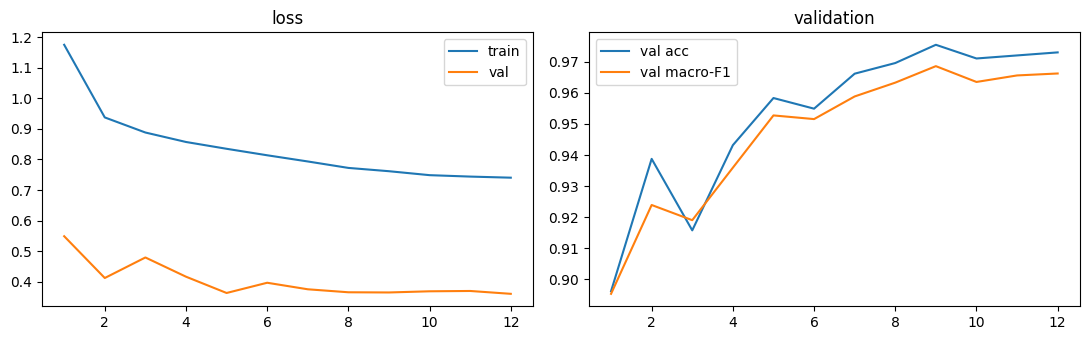

In [5]:
CKPT = CKPT_DIR / f"{SHORT}_best.pth"
best_f1, best_ep, bad, hist = -1.0, 0, 0, []
t_start = time.time()
for ep in range(1, EPOCHS + 1):
    model.train(); t0 = time.time(); tl = n = corr = 0
    for x, y in train_loader:
        x = x.to(device, non_blocking=True); y = y.to(device, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        with torch.autocast("cuda", dtype=torch.float16):
            out = model(x); loss = crit(out, y)
        scaler.scale(loss).backward(); scaler.unscale_(opt)
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update(); sched.step()
        tl += loss.item() * len(y); n += len(y); corr += (out.argmax(1) == y).sum().item()
    v = quick_eval(val_loader)
    hist.append(dict(epoch=ep, train_loss=tl / n, train_acc=corr / n, val_loss=v["loss"], val_acc=v["acc"], val_f1=v["f1"]))
    star = ""
    if v["f1"] > best_f1:
        best_f1, best_ep, bad = v["f1"], ep, 0; star = " * BEST"
        torch.save({"model_name": TIMM_NAME, "model_kwargs": MODEL_KW, "class_names": CLASS_NAMES, "num_classes": NUM_CLASSES,
                    "img_size": IMG, "mean": MEAN, "std": STD, "epoch": ep, "model_state_dict": model.state_dict()}, CKPT)
    else:
        bad += 1
    print(f"ep {ep:02d}/{EPOCHS} {time.time() - t0:5.0f}s | train loss {tl / n:.3f} acc {corr / n:.4f} | "
          f"val loss {v['loss']:.3f} acc {v['acc']:.4f} F1 {v['f1']:.4f}{star}")
    if bad >= PATIENCE:
        print("early stop"); break
train_minutes = (time.time() - t_start) / 60
pd.DataFrame(hist).to_csv(RES_DIR / f"{SHORT}_history.csv", index=False)
print(f"best epoch {best_ep}, val macro-F1 {best_f1:.4f}, train time {train_minutes:.1f} min")

h = pd.DataFrame(hist); fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(h.epoch, h.train_loss, label="train"); ax[0].plot(h.epoch, h.val_loss, label="val"); ax[0].set_title("loss"); ax[0].legend()
ax[1].plot(h.epoch, h.val_acc, label="val acc"); ax[1].plot(h.epoch, h.val_f1, label="val macro-F1"); ax[1].set_title("validation"); ax[1].legend()
plt.tight_layout(); plt.savefig(RES_DIR / f"{SHORT}_curves.png", dpi=130); plt.show()

IN-DOMAIN TEST : {'acc': 0.9957446808510638, 'macro_f1': 0.9921498821389201}
FIELD TEST     : {'acc': 0.7702702702702703, 'macro_f1': 0.6562306501547988} (74 real-world leaf crops, never trained on)
SCENE TEST     : {'acc': 0.8372093023255814, 'macro_f1': 0.7524809923969588} (43 whole real-world photos, never trained on)

                                                     precision    recall  f1-score   support

Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot      0.909     0.980     0.943        51
                       Corn_(maize)___Common_rust_      1.000     1.000     1.000       120
               Corn_(maize)___Northern_Leaf_Blight      0.990     0.960     0.975       100
                            Corn_(maize)___healthy      1.000     0.991     0.996       115
                                 Grape___Black_rot      1.000     1.000     1.000       119
                      Grape___Esca_(Black_Measles)      1.000     1.000     1.000       136
        Grape___Leaf_blight_(I

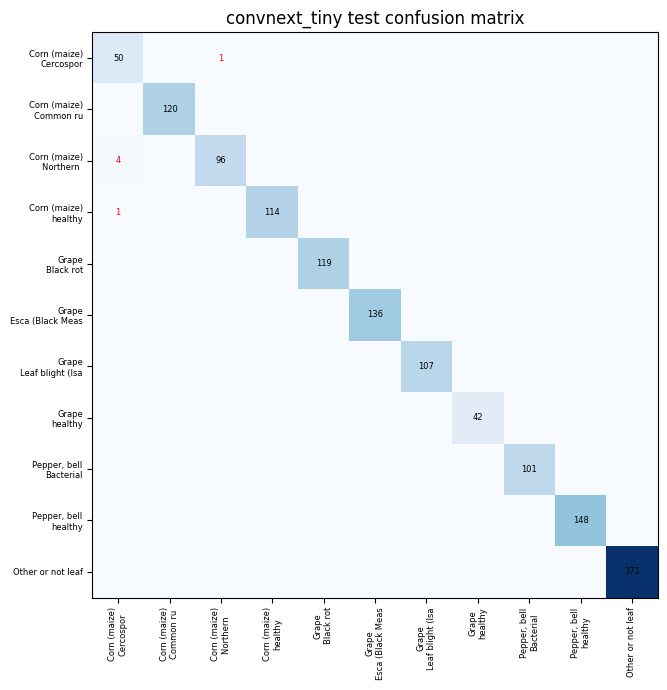

In [6]:
# reload best weights
ck = torch.load(CKPT, map_location=device, weights_only=False)
model.load_state_dict(ck["model_state_dict"]); model.eval()

def metrics(y, p):
    return dict(acc=float(accuracy_score(y, p)), macro_f1=float(f1_score(y, p, average="macro", zero_division=0)))

lg_val, ft_val, y_val = run(model, val_loader)
lg_te,  ft_te,  y_te  = run(model, test_loader)
lg_fd,  ft_fd,  y_fd  = run(model, field_loader)
lg_ood, ft_ood, _     = run(model, ood_loader)
if HAS_SCENE: lg_sc, ft_sc, y_sc = run(model, scene_loader)

res = dict(model=SHORT, timm_name=TIMM_NAME, params_m=n_params / 1e6, best_epoch=best_ep, train_minutes=train_minutes,
           ckpt_mb=os.path.getsize(CKPT) / 1e6)
res["manifest_md5"] = MANIFEST_MD5; res["split_sizes"] = {k_: len(v_) for k_, v_ in D.items()}
res["test"] = metrics(y_te, lg_te.argmax(1)); res["field"] = metrics(y_fd, lg_fd.argmax(1))
print("IN-DOMAIN TEST :", res["test"])
print("FIELD TEST     :", res["field"], f"({len(y_fd)} real-world leaf crops, never trained on)")
if HAS_SCENE:
    res["scene"] = metrics(y_sc, lg_sc.argmax(1))
    print("SCENE TEST     :", res["scene"], f"({len(y_sc)} whole real-world photos, never trained on)")
print("\n", classification_report(y_te, lg_te.argmax(1), target_names=CLASS_NAMES, digits=3, zero_division=0))
print("FIELD report:\n", classification_report(y_fd, lg_fd.argmax(1), labels=list(range(NUM_CLASSES)),
      target_names=CLASS_NAMES, digits=3, zero_division=0))

cm = confusion_matrix(y_te, lg_te.argmax(1), labels=list(range(NUM_CLASSES)))
fig, ax = plt.subplots(figsize=(8, 7)); ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(NUM_CLASSES)); ax.set_yticks(range(NUM_CLASSES))
short = [c.replace("___", "\n").replace("_", " ")[:22] for c in CLASS_NAMES]
ax.set_xticklabels(short, rotation=90, fontsize=6); ax.set_yticklabels(short, fontsize=6)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if cm[i, j]: ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=6, color="red" if i != j else "black")
ax.set_title(f"{SHORT} test confusion matrix"); plt.tight_layout(); plt.savefig(RES_DIR / f"{SHORT}_confusion.png", dpi=130); plt.show()

In [7]:
# ---------------- calibration: temperature scaling + ECE ----------------
def softmax(z):
    z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)

def ece(probs, y, bins=15):
    conf, pred = probs.max(1), probs.argmax(1); acc = pred == y; e = 0.0
    edges = np.linspace(0, 1, bins + 1)
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): e += m.mean() * abs(acc[m].mean() - conf[m].mean())
    return float(e)

def fit_temperature(logits, y):
    lg = torch.tensor(logits, dtype=torch.float32); yt = torch.tensor(y)
    logT = torch.nn.Parameter(torch.zeros(1))
    o = torch.optim.LBFGS([logT], lr=0.1, max_iter=200)
    def closure():
        o.zero_grad(); l = F.cross_entropy(lg / logT.exp(), yt); l.backward(); return l
    o.step(closure); return float(logT.exp().item())

T = fit_temperature(lg_val, y_val)
res["temperature"] = T
res["ece_before"] = ece(softmax(lg_te), y_te); res["ece_after"] = ece(softmax(lg_te / T), y_te)
print(f"temperature T = {T:.3f} | ECE test: {res['ece_before']:.4f} -> {res['ece_after']:.4f}")

temperature T = 0.502 | ECE test: 0.1846 -> 0.0193


In [8]:
# ---------------- unknown-image detection ----------------
def fit_maha(feats, y, n_cls):
    mu = np.stack([feats[y == c].mean(0) for c in range(n_cls)]).astype(np.float64)
    cen = (feats - mu[y]).astype(np.float64)
    cov = cen.T @ cen / len(cen)
    cov += 1e-3 * np.trace(cov) / cov.shape[0] * np.eye(cov.shape[0])      # ridge
    return mu, np.linalg.inv(cov)

def maha_score(feats, mu, P):
    """distance to nearest in-scope class centroid (higher = more unusual)"""
    f = feats.astype(np.float64); A = f @ P
    t1 = (A * f).sum(1)[:, None]; t2 = A @ mu.T; t3 = ((mu @ P) * mu).sum(1)[None, :]
    return (t1 - 2 * t2 + t3).min(1)

lg_tr, ft_tr, y_tr = run(model, train_eval_loader)          # in-scope training images only (classes 0-9)
mu, P = fit_maha(ft_tr, y_tr, OTHER_IDX)

def scores(lg, ft):
    pr = softmax(lg / T)
    return {"msp": 1 - pr.max(1),
            "energy": -T * logsumexp(lg / T, axis=1),
            "p_other": pr[:, OTHER_IDX],
            "mahalanobis": maha_score(ft, mu, P)}

# ID set = in-scope images of test + field_test ; OOD set = ood_test
id_mask_te = y_te < OTHER_IDX
S_id = {}
for k in ["msp", "energy", "p_other", "mahalanobis"]:
    parts = [scores(lg_te, ft_te)[k][id_mask_te], scores(lg_fd, ft_fd)[k]]
    if HAS_SCENE: parts.append(scores(lg_sc, ft_sc)[k])
    S_id[k] = np.concatenate(parts)
S_ood = scores(lg_ood, ft_ood)

def ood_metrics(id_s, ood_s):
    y = np.r_[np.zeros(len(id_s)), np.ones(len(ood_s))]
    thr = np.quantile(id_s, 0.95)
    return dict(auroc=float(roc_auc_score(y, np.r_[id_s, ood_s])), fpr_at_95tpr=float((ood_s <= thr).mean()))

res["ood"] = {k: ood_metrics(S_id[k], S_ood[k]) for k in S_id}
print(f"{len(S_ood['msp'])} OOD images vs {len(S_id['msp'])} in-distribution images")
for k, v in res["ood"].items():
    print(f"  {k:12s} AUROC {v['auroc']:.4f} | OOD wrongly accepted at 95% ID-accept: {v['fpr_at_95tpr']:.1%}")

# ---------- the actual deployment rule ----------
# reject if (argmax == Other)  OR  (Mahalanobis > threshold calibrated on VAL in-scope images, 95th percentile)
sv = scores(lg_val, ft_val); thr_maha = float(np.quantile(sv["mahalanobis"][y_val < OTHER_IDX], 0.95))

def decide(lg, ft):
    sc = scores(lg, ft)
    return (lg.argmax(1) == OTHER_IDX) | (sc["mahalanobis"] > thr_maha)

rej_te, rej_fd, rej_ood = decide(lg_te, ft_te), decide(lg_fd, ft_fd), decide(lg_ood, ft_ood)
rej_sc = decide(lg_sc, ft_sc) if HAS_SCENE else None
acc_mask = id_mask_te & ~rej_te
dep = dict(maha_threshold=thr_maha,
           id_accept_test=float((~rej_te[id_mask_te]).mean()), id_accept_field=float((~rej_fd).mean()),
           id_accept_scene=(float((~rej_sc).mean()) if HAS_SCENE else None),
           acc_on_accepted_scene=(float((lg_sc.argmax(1)[~rej_sc] == y_sc[~rej_sc]).mean()) if HAS_SCENE and (~rej_sc).any() else None),
           field_end_to_end=float((~rej_fd & (lg_fd.argmax(1) == y_fd)).mean()),     # real leaf, ACCEPTED and the right class
           scene_end_to_end=(float((~rej_sc & (lg_sc.argmax(1) == y_sc)).mean()) if HAS_SCENE else None),
           acc_on_accepted_test=float((lg_te.argmax(1)[acc_mask] == y_te[acc_mask]).mean()),
           acc_on_accepted_field=float((lg_fd.argmax(1)[~rej_fd] == y_fd[~rej_fd]).mean()) if (~rej_fd).any() else None,
           ood_rejected=float(rej_ood.mean()), ood_rejected_by_source={})
for s, g in D["ood_test"].groupby("source"):
    dep["ood_rejected_by_source"][s] = dict(n=int(len(g)), rejected=float(rej_ood[g.index.values].mean()))
_rj = [v_["rejected"] for v_ in dep["ood_rejected_by_source"].values()]
dep["ood_rejected_macro"] = float(np.mean(_rj)); dep["ood_rejected_worst"] = float(np.min(_rj))     # every source counts equally (apple/tomato is ~40% of the images)
dep["ood_worst_source"] = min(dep["ood_rejected_by_source"], key=lambda s_: dep["ood_rejected_by_source"][s_]["rejected"])
res["deploy"] = dep
print("\nDEPLOYMENT RULE")
print(f"  real leaves accepted: test {dep['id_accept_test']:.1%} | field crops {dep['id_accept_field']:.1%} | whole photos {dep['id_accept_scene']}")
print(f"  accuracy on accepted: test {dep['acc_on_accepted_test']:.2%} | field {dep['acc_on_accepted_field']}")
print(f"  real leaf accepted AND correct: field {dep['field_end_to_end']:.1%} | whole photos {dep['scene_end_to_end']}")
print(f"  unknown images rejected: pooled {dep['ood_rejected']:.1%} | average over sources {dep['ood_rejected_macro']:.1%} | WORST source {dep['ood_rejected_worst']:.1%} ({dep['ood_worst_source']})")
for s, v in dep["ood_rejected_by_source"].items():
    print(f"     {s:28s} n={v['n']:4d}  rejected {v['rejected']:.1%}")

# artifacts for the Flask backend
np.savez(CKPT_DIR / f"{SHORT}_ood_stats.npz", class_means=mu, precision=P)
json.dump({"temperature": T, "mahalanobis": thr_maha, "other_index": OTHER_IDX, "class_names": CLASS_NAMES},
          open(CKPT_DIR / f"{SHORT}_ood_thresholds.json", "w"), indent=2)

2324 OOD images vs 1156 in-distribution images
  msp          AUROC 0.9806 | OOD wrongly accepted at 95% ID-accept: 1.5%
  energy       AUROC 0.9895 | OOD wrongly accepted at 95% ID-accept: 1.7%
  p_other      AUROC 0.9981 | OOD wrongly accepted at 95% ID-accept: 0.4%
  mahalanobis  AUROC 0.9964 | OOD wrongly accepted at 95% ID-accept: 0.4%

DEPLOYMENT RULE
  real leaves accepted: test 99.7% | field crops 81.1% | whole photos 0.8837209302325582
  accuracy on accepted: test 99.52% | field 0.85
  real leaf accepted AND correct: field 68.9% | whole photos 0.7674418604651163
  unknown images rejected: pooled 98.8% | average over sources 98.4% | WORST source 96.3% (plantdoc_other_crops_TEST)
     caltech_unseen_objects       n= 468  rejected 100.0%
     heldout_pv_apple_tomato      n= 840  rejected 98.7%
     pets_ood                     n= 500  rejected 100.0%
     plantdoc_other_crops_TEST    n= 349  rejected 96.3%
     plantdoc_other_scene_TEST    n= 167  rejected 97.0%


In [9]:
# ---------------- robustness (test split, all 11 classes) ----------------
conds = ["clean", "dark", "bright", "blur", "jpeg", "rotate", "crop", "noise", "lowres"]
rob = {}
for c in conds:
    np.random.seed(SEED)
    lg, _, y = run(model, loader(D["test"], eval_tf, cond=c))
    rob[c] = metrics(y, lg.argmax(1)); print(f"{c:8s} acc {rob[c]['acc']:.4f}  macro-F1 {rob[c]['macro_f1']:.4f}")
res["robustness"] = rob
res["robustness_mean_acc_perturbed"] = float(np.mean([rob[c]["acc"] for c in conds if c != "clean"]))
res["robustness_worst_acc"] = float(min(rob[c]["acc"] for c in conds if c != "clean"))

clean    acc 0.9957  macro-F1 0.9921
dark     acc 0.9979  macro-F1 0.9960
bright   acc 0.9957  macro-F1 0.9921
blur     acc 0.9922  macro-F1 0.9861
jpeg     acc 0.9936  macro-F1 0.9879
rotate   acc 0.9950  macro-F1 0.9909
crop     acc 0.9922  macro-F1 0.9868
noise    acc 0.9943  macro-F1 0.9896
lowres   acc 0.9936  macro-F1 0.9890


In [10]:
# ---------------- size + latency ----------------
def bench(m, dev, n, warm=10):
    x = torch.randn(1, 3, IMG, IMG, device=dev); m = m.to(dev).eval(); ts = []
    with torch.inference_mode():
        for i in range(warm + n):
            if dev.type == "cuda": torch.cuda.synchronize()
            t = time.perf_counter(); m(x)
            if dev.type == "cuda": torch.cuda.synchronize()
            if i >= warm: ts.append((time.perf_counter() - t) * 1000)
    return dict(mean_ms=float(np.mean(ts)), p50_ms=float(np.percentile(ts, 50)), p95_ms=float(np.percentile(ts, 95)))

res["latency_gpu_fp32"] = bench(model, torch.device("cuda"), 100)
res["latency_cpu_fp32"] = bench(model, torch.device("cpu"), 30)
model.to(device)
print("GPU:", res["latency_gpu_fp32"]); print("CPU:", res["latency_cpu_fp32"])
print(f"params {res['params_m']:.2f} M | checkpoint {res['ckpt_mb']:.0f} MB")

json.dump(res, open(RES_DIR / f"{SHORT}_metrics.json", "w"), indent=2)
print("\nsaved:", RES_DIR / f"{SHORT}_metrics.json")

GPU: {'mean_ms': 6.403400650028743, 'p50_ms': 5.890808499998457, 'p95_ms': 10.106126800224047}
CPU: {'mean_ms': 130.394340466637, 'p50_ms': 127.46193099997072, 'p95_ms': 144.79514730012397}
params 27.83 M | checkpoint 111 MB

saved: /content/drive/MyDrive/plant-disease-v2/results/convnext_tiny_metrics.json


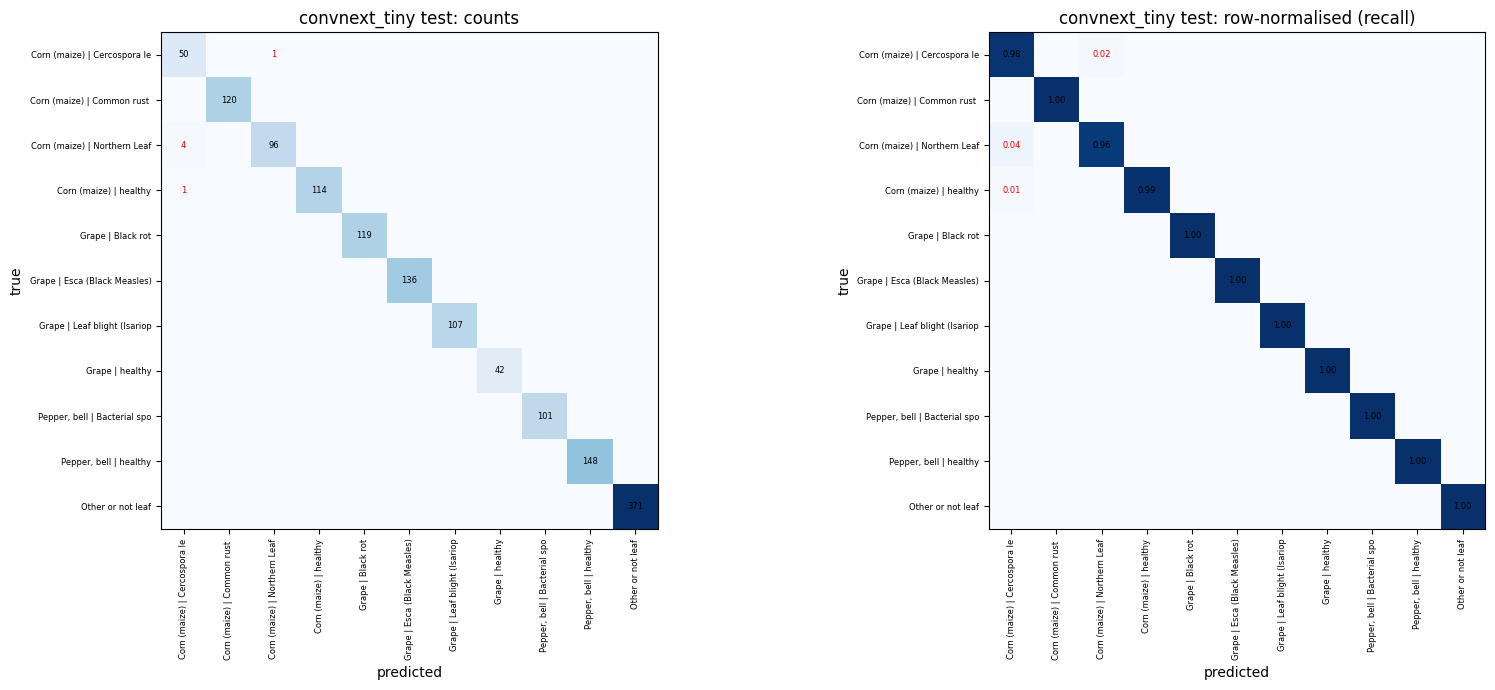

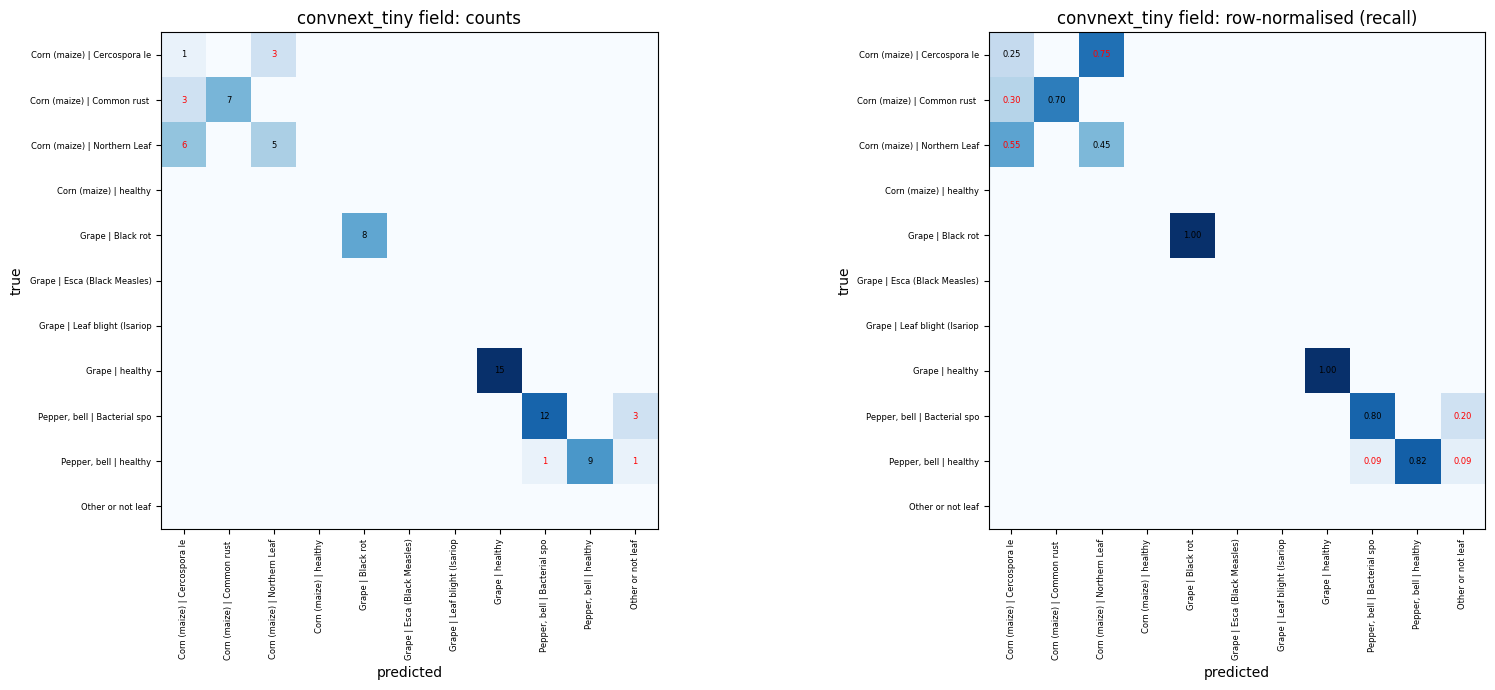

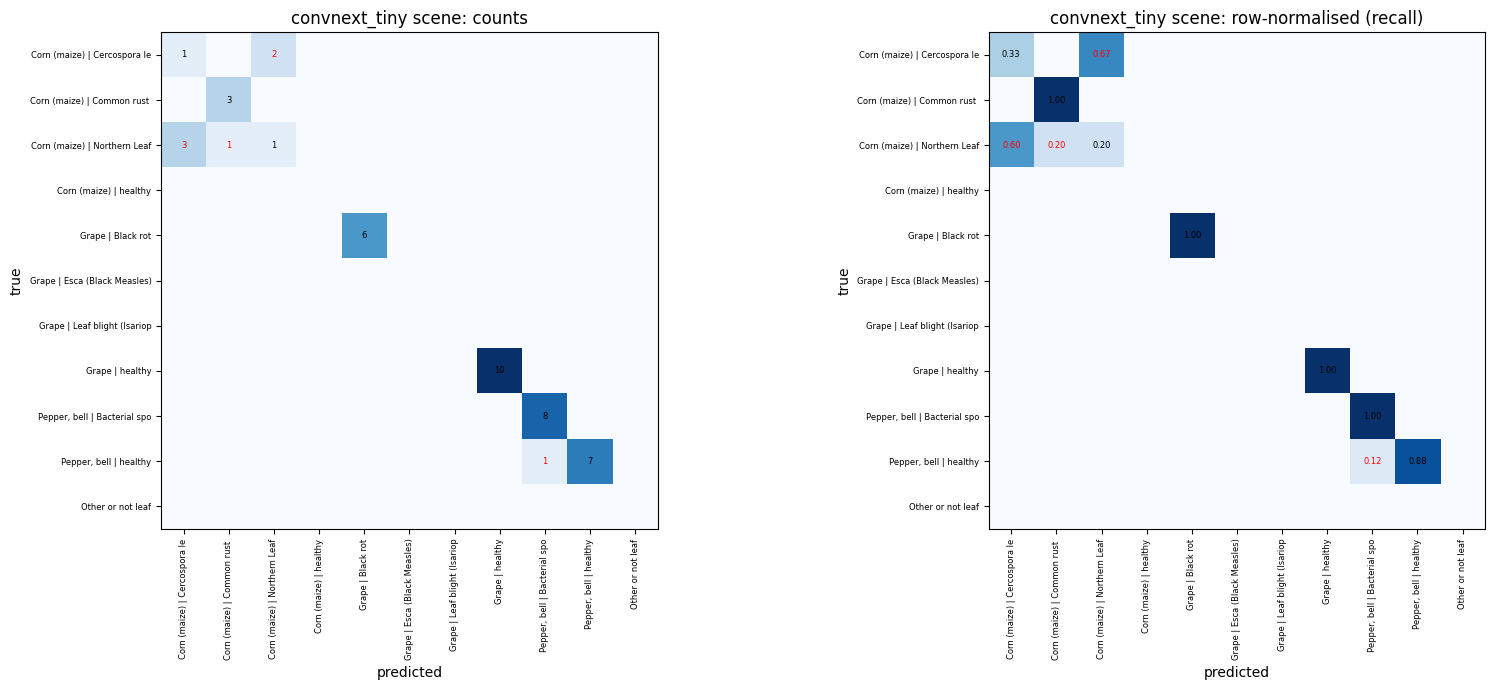

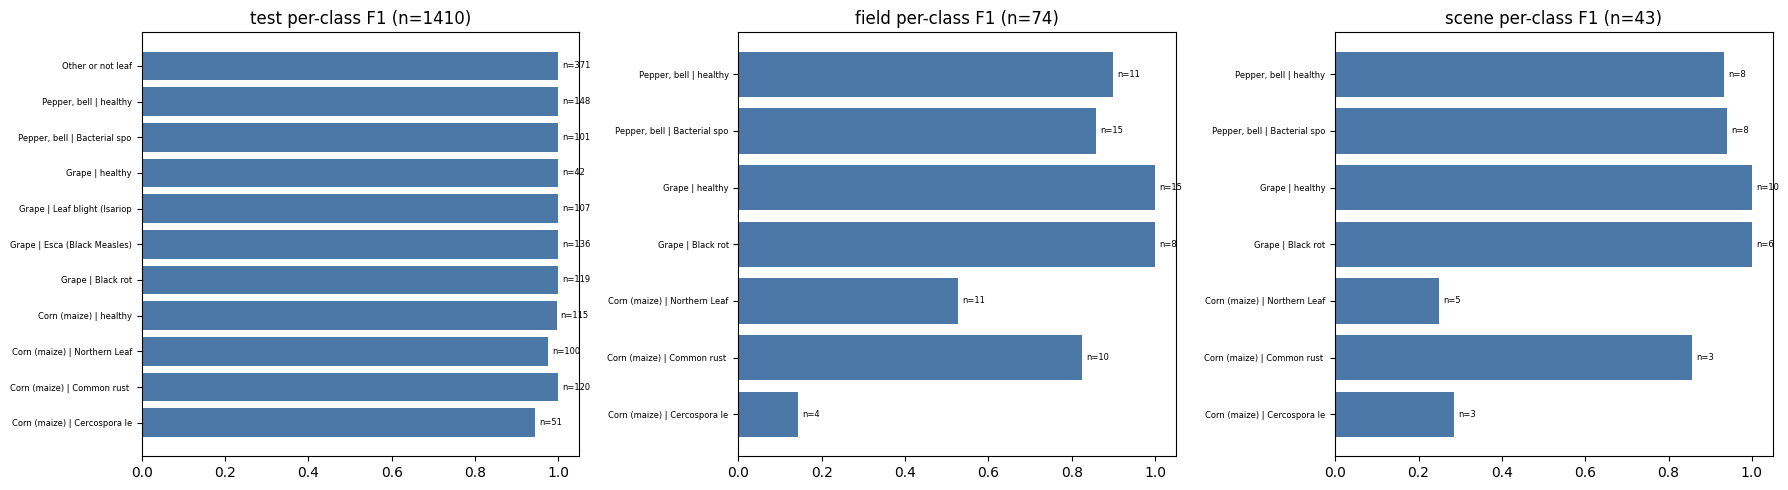

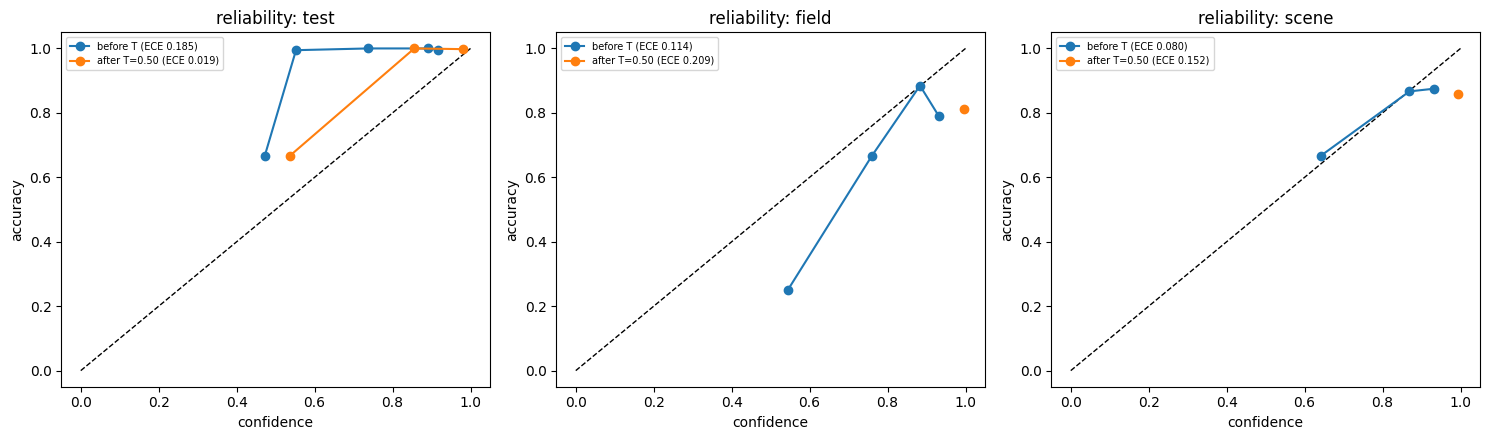

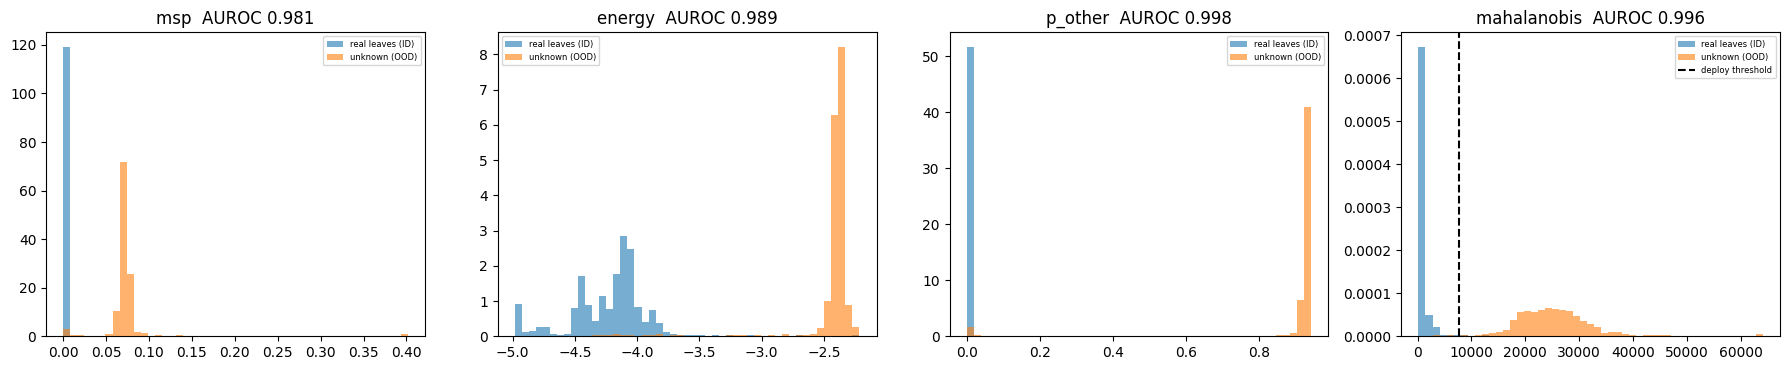

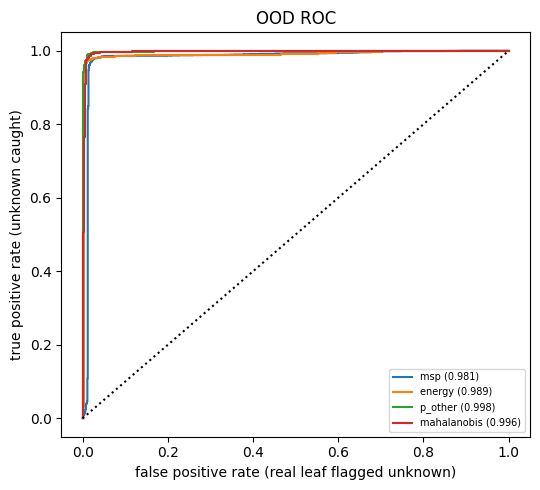

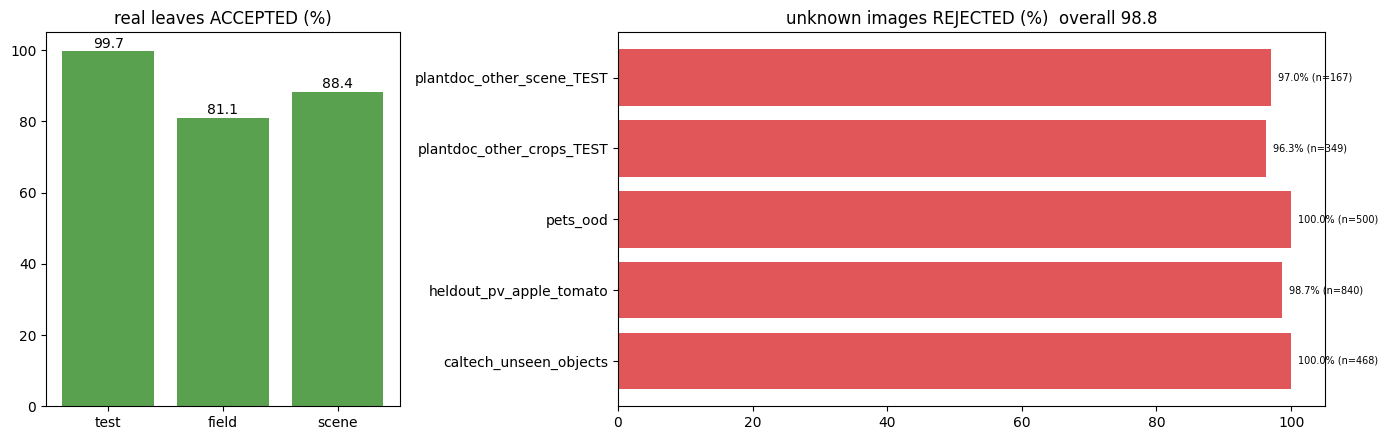

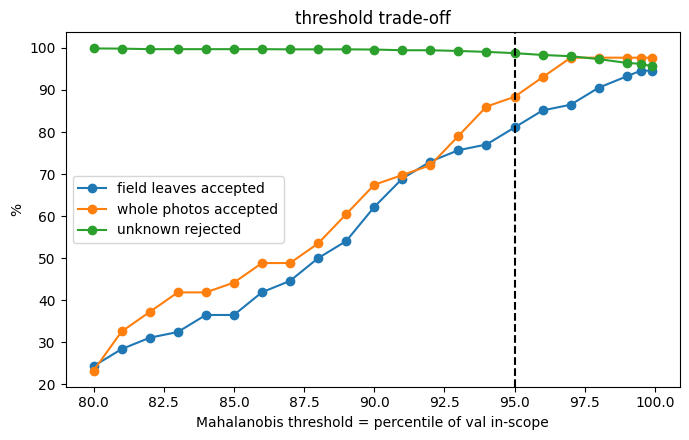

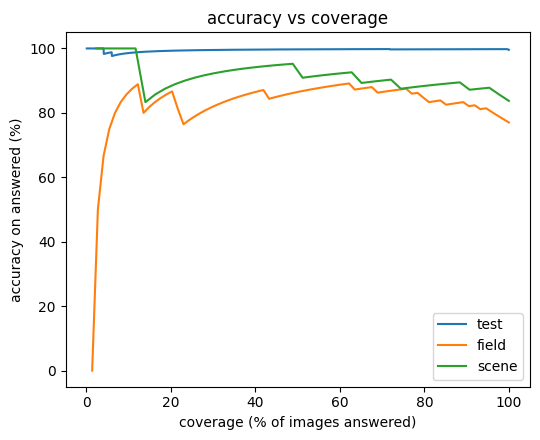

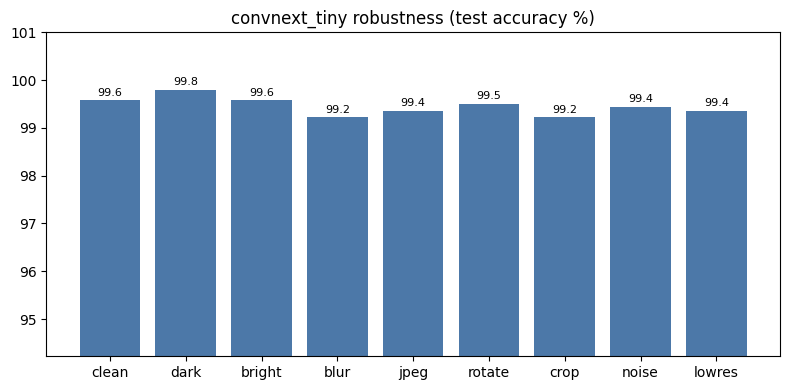

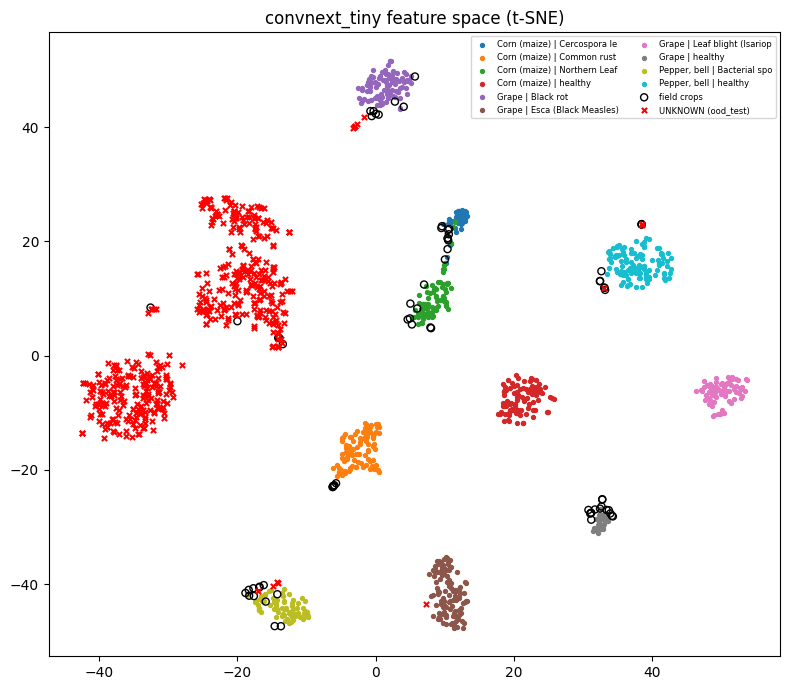

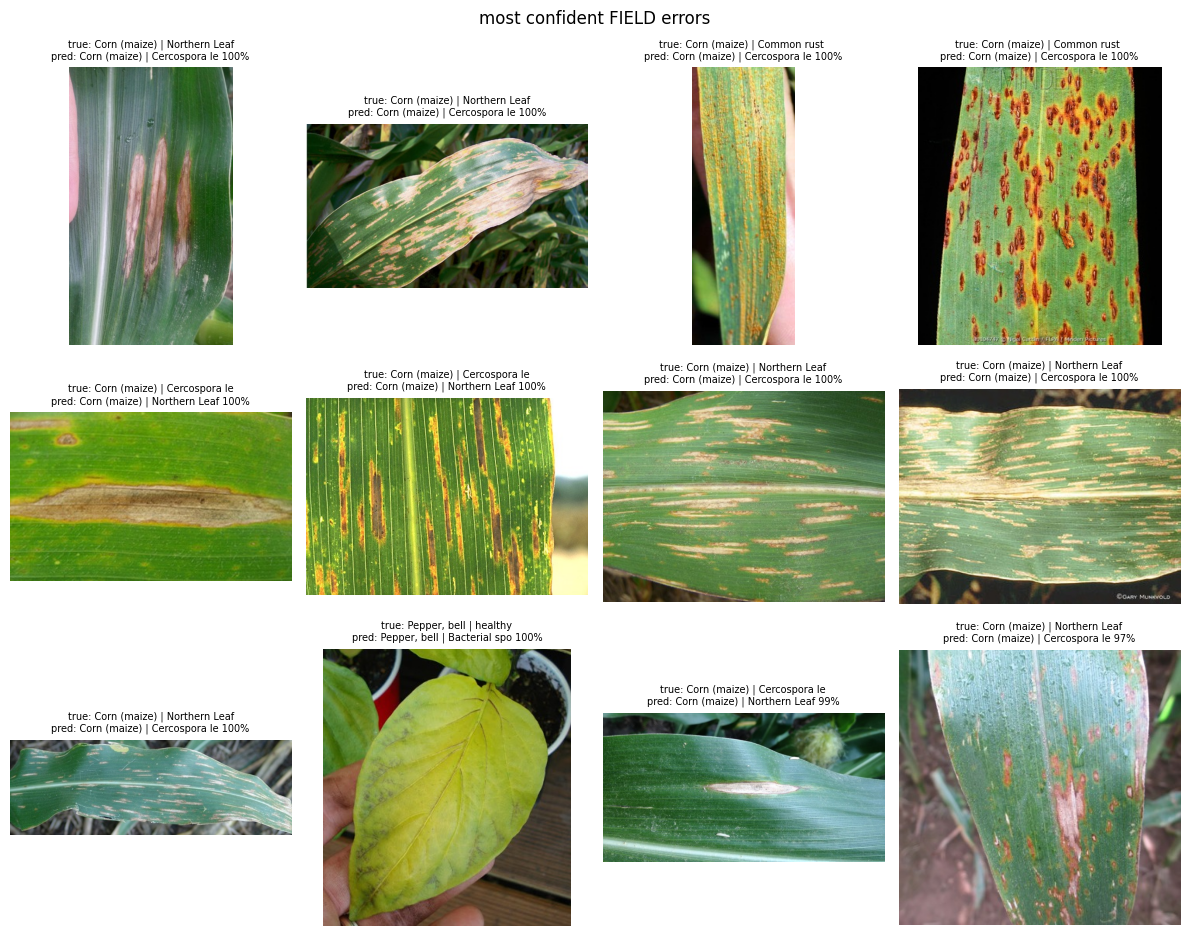

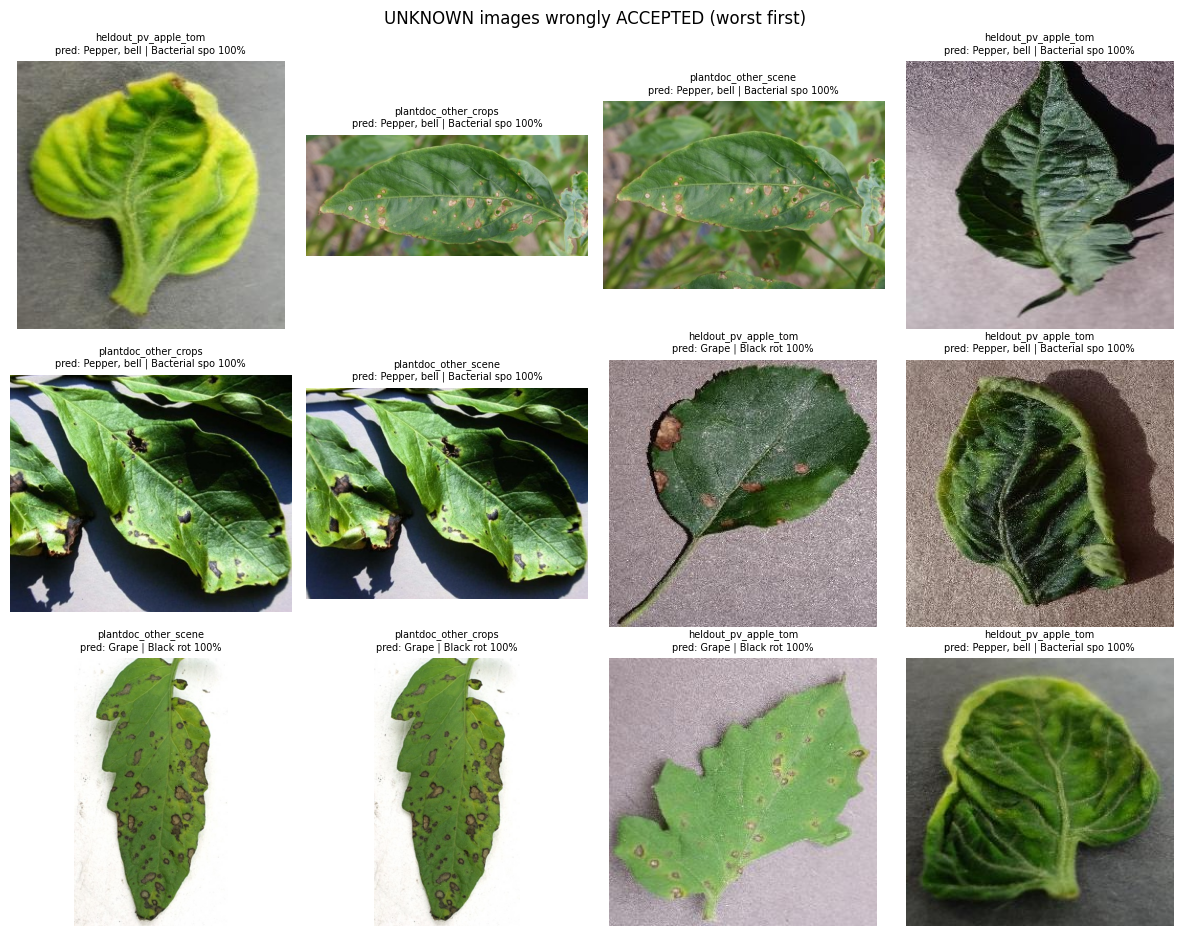

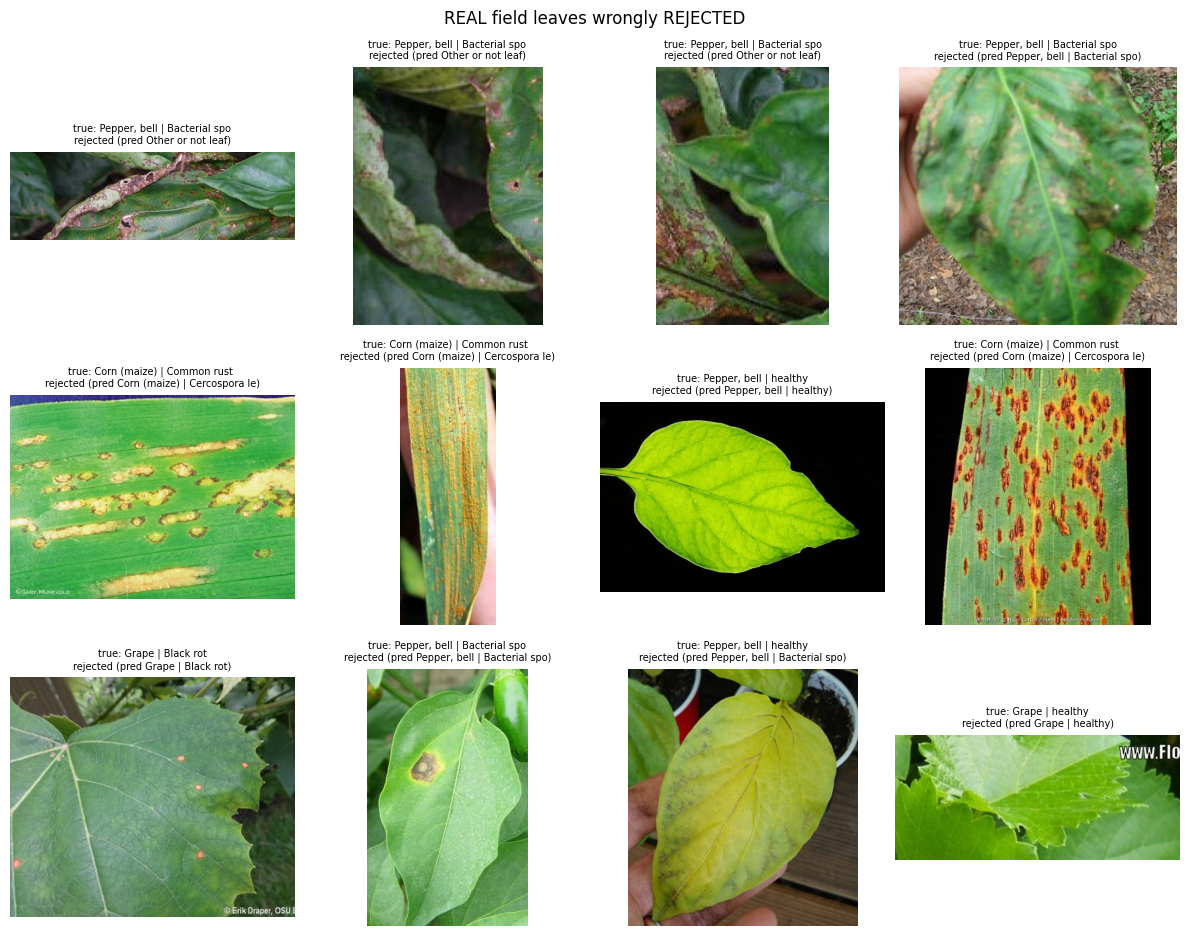

saved to /content/drive/MyDrive/plant-disease-v2/results :
  convnext_tiny_cm_test.png
  convnext_tiny_cm_field.png
  convnext_tiny_cm_scene.png
  convnext_tiny_per_class_f1.png
  convnext_tiny_reliability.png
  convnext_tiny_ood_histograms.png
  convnext_tiny_ood_roc.png
  convnext_tiny_deploy_rule.png
  convnext_tiny_threshold_sweep.png
  convnext_tiny_accuracy_coverage.png
  convnext_tiny_robustness.png
  convnext_tiny_tsne.png
  convnext_tiny_err_field.png
  convnext_tiny_err_ood_accepted.png
  convnext_tiny_err_field_rejected.png


In [11]:
# ---------------- evaluation plots + saved raw outputs (everything goes to Drive results/) ----------------
from sklearn.metrics import roc_curve, precision_recall_fscore_support
from sklearn.manifold import TSNE

LAB = list(range(NUM_CLASSES))
short = [c.replace("___", " | ").replace("_", " ")[:28] for c in CLASS_NAMES]
saved = []
def save(fig, name):
    fig.tight_layout(); p = RES_DIR / f"{SHORT}_{name}.png"; fig.savefig(p, dpi=140); saved.append(p.name); plt.show()

sets = {"test": (lg_te, y_te), "field": (lg_fd, y_fd)}
if HAS_SCENE: sets["scene"] = (lg_sc, y_sc)

# 1) confusion matrices (counts + row-normalised) for test / field / scene
for nm, (lg, y) in sets.items():
    p = lg.argmax(1); cm = confusion_matrix(y, p, labels=LAB); rs = cm.sum(1, keepdims=True)
    cmn = np.divide(cm, rs, out=np.zeros(cm.shape), where=rs > 0)
    fig, ax = plt.subplots(1, 2, figsize=(17, 7))
    for a, M, t in [(ax[0], cm, "counts"), (ax[1], cmn, "row-normalised (recall)")]:
        a.imshow(M, cmap="Blues"); a.set_title(f"{SHORT} {nm}: {t}")
        a.set_xticks(LAB); a.set_yticks(LAB); a.set_xticklabels(short, rotation=90, fontsize=6); a.set_yticklabels(short, fontsize=6)
        a.set_xlabel("predicted"); a.set_ylabel("true")
        for i in LAB:
            for j in LAB:
                if M[i, j]: a.text(j, i, f"{M[i, j]:.2f}" if M is cmn else int(M[i, j]), ha="center", va="center", fontsize=6, color="red" if i != j else "black")
    save(fig, f"cm_{nm}")

# 2) per-class precision / recall / F1 (+ CSV) and F1 bars
fig, ax = plt.subplots(1, len(sets), figsize=(6 * len(sets), 5), sharey=False); ax = np.atleast_1d(ax)
for a, (nm, (lg, y)) in zip(ax, sets.items()):
    pr, rc, f1, sup = precision_recall_fscore_support(y, lg.argmax(1), labels=LAB, zero_division=0)
    rep = pd.DataFrame(dict(cls=CLASS_NAMES, precision=pr, recall=rc, f1=f1, support=sup)); rep.to_csv(RES_DIR / f"{SHORT}_report_{nm}.csv", index=False)
    r2 = rep[rep.support > 0]; a.barh([short[i] for i in r2.index], r2.f1, color="#4c78a8"); a.set_xlim(0, 1.05); a.set_title(f"{nm} per-class F1 (n={int(sup.sum())})")
    for k, (v, s) in enumerate(zip(r2.f1, r2.support)): a.text(v + .01, k, f"n={int(s)}", va="center", fontsize=6)
    a.tick_params(axis="y", labelsize=6)
save(fig, "per_class_f1")

# 3) reliability diagrams (calibration) before / after temperature scaling
def rel_curve(pr, y, bins=10):
    conf, pred = pr.max(1), pr.argmax(1); ok = pred == y; edges = np.linspace(0, 1, bins + 1); xs, ys, ns = [], [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() >= 3: xs.append(conf[m].mean()); ys.append(ok[m].mean()); ns.append(m.sum())
    return xs, ys
fig, ax = plt.subplots(1, len(sets), figsize=(5 * len(sets), 4.5)); ax = np.atleast_1d(ax)
for a, (nm, (lg, y)) in zip(ax, sets.items()):
    a.plot([0, 1], [0, 1], "k--", lw=1)
    for lab, z in [("before T", lg), (f"after T={T:.2f}", lg / T)]:
        xs, ys = rel_curve(softmax(z), y); a.plot(xs, ys, "o-", label=f"{lab} (ECE {ece(softmax(z), y):.3f})")
    a.set_title(f"reliability: {nm}"); a.set_xlabel("confidence"); a.set_ylabel("accuracy"); a.legend(fontsize=7)
save(fig, "reliability")

# 4) unknown-image detection: score histograms + ROC curves (ID = real leaves, OOD = ood_test)
keys = ["msp", "energy", "p_other", "mahalanobis"]
fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
for a, k in zip(ax, keys):
    lo, hi = np.percentile(np.r_[S_id[k], S_ood[k]], [0.5, 99.5]); bins = np.linspace(lo, hi, 50)
    a.hist(np.clip(S_id[k], lo, hi), bins, alpha=.6, density=True, label="real leaves (ID)"); a.hist(np.clip(S_ood[k], lo, hi), bins, alpha=.6, density=True, label="unknown (OOD)")
    if k == "mahalanobis": a.axvline(thr_maha, color="k", ls="--", label="deploy threshold")
    a.set_title(f"{k}  AUROC {res['ood'][k]['auroc']:.3f}"); a.legend(fontsize=6)
save(fig, "ood_histograms")
fig, ax = plt.subplots(figsize=(5.5, 5))
for k in keys:
    yy = np.r_[np.zeros(len(S_id[k])), np.ones(len(S_ood[k]))]; fpr, tpr, _ = roc_curve(yy, np.r_[S_id[k], S_ood[k]])
    ax.plot(fpr, tpr, label=f"{k} ({res['ood'][k]['auroc']:.3f})")
ax.plot([0, 1], [0, 1], "k:"); ax.set_xlabel("false positive rate (real leaf flagged unknown)"); ax.set_ylabel("true positive rate (unknown caught)"); ax.set_title("OOD ROC"); ax.legend(fontsize=7)
save(fig, "ood_roc")

# 5) deployment rule: acceptance of real leaves vs rejection of unknown images, per source
acc_sets = {"test": dep["id_accept_test"], "field": dep["id_accept_field"]}
if HAS_SCENE: acc_sets["scene"] = dep["id_accept_scene"]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw=dict(width_ratios=[1, 2]))
ax[0].bar(list(acc_sets), [v * 100 for v in acc_sets.values()], color="#59a14f"); ax[0].set_ylim(0, 105); ax[0].set_title("real leaves ACCEPTED (%)")
for i, v in enumerate(acc_sets.values()): ax[0].text(i, v * 100 + 1, f"{v * 100:.1f}", ha="center")
srcs = list(dep["ood_rejected_by_source"]); vals = [dep["ood_rejected_by_source"][s]["rejected"] * 100 for s in srcs]
ax[1].barh(srcs, vals, color="#e15759"); ax[1].set_xlim(0, 105); ax[1].set_title(f"unknown images REJECTED (%)  overall {dep['ood_rejected'] * 100:.1f}")
for i, (s, v) in enumerate(zip(srcs, vals)): ax[1].text(v + 1, i, f"{v:.1f}% (n={dep['ood_rejected_by_source'][s]['n']})", va="center", fontsize=7)
save(fig, "deploy_rule")

# 6) threshold sweep: the trade-off behind the 95th-percentile choice
qs = np.r_[np.linspace(80, 99, 20), 99.5, 99.9]; ref = sv["mahalanobis"][y_val < OTHER_IDX]
def rate(lg, ft, thr): return ((lg.argmax(1) == OTHER_IDX) | (maha_score(ft, mu, P) > thr))
rows_sw = []
for q in qs:
    th = np.quantile(ref, q / 100)
    rows_sw.append(dict(q=q, field_accept=1 - rate(lg_fd, ft_fd, th).mean(), ood_reject=rate(lg_ood, ft_ood, th).mean(),
                        scene_accept=(1 - rate(lg_sc, ft_sc, th).mean()) if HAS_SCENE else np.nan))
sw = pd.DataFrame(rows_sw); sw.to_csv(RES_DIR / f"{SHORT}_threshold_sweep.csv", index=False)
fig, ax = plt.subplots(figsize=(7, 4.5)); ax.plot(sw.q, sw.field_accept * 100, "o-", label="field leaves accepted")
if HAS_SCENE: ax.plot(sw.q, sw.scene_accept * 100, "o-", label="whole photos accepted")
ax.plot(sw.q, sw.ood_reject * 100, "o-", label="unknown rejected"); ax.axvline(95, color="k", ls="--"); ax.set_xlabel("Mahalanobis threshold = percentile of val in-scope"); ax.set_ylabel("%"); ax.legend(); ax.set_title("threshold trade-off")
save(fig, "threshold_sweep")

# 7) selective prediction: accuracy vs coverage on field images (keep only the most confident)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
for nm, (lg, y) in sets.items():
    pr = softmax(lg / T); o = np.argsort(-pr.max(1)); ok = (pr.argmax(1) == y)[o]; cov = np.arange(1, len(o) + 1) / len(o)
    ax.plot(cov * 100, np.cumsum(ok) / np.arange(1, len(o) + 1) * 100, label=nm)
ax.set_xlabel("coverage (% of images answered)"); ax.set_ylabel("accuracy on answered (%)"); ax.legend(); ax.set_title("accuracy vs coverage")
save(fig, "accuracy_coverage")

# 8) robustness bars
fig, ax = plt.subplots(figsize=(8, 4)); ax.bar(list(rob), [rob[c]["acc"] * 100 for c in rob], color="#4c78a8"); ax.set_ylim(max(0, min(rob[c]["acc"] for c in rob) * 100 - 5), 101)
for i, c in enumerate(rob): ax.text(i, rob[c]["acc"] * 100 + .1, f"{rob[c]['acc'] * 100:.1f}", ha="center", fontsize=8)
ax.set_title(f"{SHORT} robustness (test accuracy %)"); save(fig, "robustness")

# 9) feature-space map (t-SNE): do unknown images sit away from the real-leaf clusters?
rs = np.random.RandomState(SEED); pick = lambda n, k: rs.choice(n, min(n, k), replace=False)
i_te = np.where(y_te < OTHER_IDX)[0]; i_te = i_te[pick(len(i_te), 800)]; i_fd = pick(len(y_fd), 300); i_oo = pick(len(ft_ood), 500)
Z = TSNE(2, perplexity=30, init="pca", random_state=SEED).fit_transform(np.concatenate([ft_te[i_te], ft_fd[i_fd], ft_ood[i_oo]]))
a, b = len(i_te), len(i_te) + len(i_fd)
fig, ax = plt.subplots(figsize=(8, 7)); cmap = plt.get_cmap("tab10")
for c in range(OTHER_IDX):
    m = y_te[i_te] == c; ax.scatter(Z[:a][m, 0], Z[:a][m, 1], s=8, color=cmap(c), label=short[c])
ax.scatter(Z[a:b, 0], Z[a:b, 1], s=26, facecolors="none", edgecolors="k", label="field crops")
ax.scatter(Z[b:, 0], Z[b:, 1], s=14, marker="x", color="red", label="UNKNOWN (ood_test)"); ax.legend(fontsize=6, ncol=2); ax.set_title(f"{SHORT} feature space (t-SNE)")
save(fig, "tsne")

# 10) look at the mistakes: confident field errors, unknown images wrongly accepted, real leaves wrongly rejected
def gallery(df_, idx, titles, name, ttl, n=12):
    idx = list(idx)[:n]
    if not idx: print("(none) ", ttl); return
    fig, axs = plt.subplots(3, 4, figsize=(12, 9.5)); axs = axs.ravel()
    for a in axs: a.axis("off")
    for a, i, t in zip(axs, idx, titles[:n]):
        a.imshow(Image.open(DATA / df_.path.iloc[i]).convert("RGB")); a.set_title(t, fontsize=7)
    fig.suptitle(ttl); save(fig, name)
pf = softmax(lg_fd / T); wrong = np.where(pf.argmax(1) != y_fd)[0]; wrong = wrong[np.argsort(-pf.max(1)[wrong])]
gallery(D["field_test"], wrong, [f"true: {short[y_fd[i]]}\npred: {short[pf[i].argmax()]} {pf[i].max() * 100:.0f}%" for i in wrong], "err_field", "most confident FIELD errors")
po = softmax(lg_ood / T); acc_o = np.where(~rej_ood)[0]; acc_o = acc_o[np.argsort(-po.max(1)[acc_o])]
gallery(D["ood_test"], acc_o, [f"{D['ood_test'].source.iloc[i][:20]}\npred: {short[po[i].argmax()]} {po[i].max() * 100:.0f}%" for i in acc_o], "err_ood_accepted", "UNKNOWN images wrongly ACCEPTED (worst first)")
rj = np.where(rej_fd)[0]
gallery(D["field_test"], rj, [f"true: {short[y_fd[i]]}\nrejected (pred {short[pf[i].argmax()]})" for i in rj], "err_field_rejected", "REAL field leaves wrongly REJECTED")

# 11) raw outputs for notebook 05 (overlays, bootstrap CIs)
np.savez_compressed(RES_DIR / f"{SHORT}_outputs.npz", lg_te=lg_te, y_te=y_te, lg_fd=lg_fd, y_fd=y_fd,
    lg_sc=lg_sc if HAS_SCENE else np.zeros((0, NUM_CLASSES)), y_sc=y_sc if HAS_SCENE else np.zeros(0, int), T=T,
    **{f"id_{k}": S_id[k] for k in keys}, **{f"ood_{k}": S_ood[k] for k in keys}, ood_source=D["ood_test"].source.values.astype(str), ood_rejected=rej_ood)
print("saved to", RES_DIR, ":\n  " + "\n  ".join(saved))


In [32]:
# ---------------- try your OWN images (Taylor Swift, an apple leaf, a corn leaf...) ----------------
def predict_image(path):
    img = Image.open(path).convert("RGB")
    x = eval_tf(img).unsqueeze(0).to(device)
    with torch.inference_mode(), torch.autocast("cuda", dtype=torch.float16):
        f = model.forward_head(model.forward_features(x), pre_logits=True); lg = model.get_classifier()(f)
    lg = lg.float().cpu().numpy(); ft = f.float().cpu().numpy()
    pr = softmax(lg / T)[0]; top = pr.argsort()[::-1][:3]
    m = float(maha_score(ft, mu, P)[0])
    rejected = bool(top[0] == OTHER_IDX or m > thr_maha)
    print(f"\n{Path(path).name}")
    for i in top: print(f"   {pr[i] * 100:5.1f}%  {CLASS_NAMES[i]}")
    print(f"   Mahalanobis {m:.1f} (threshold {thr_maha:.1f})  ->  " + ("REJECTED: not a supported leaf" if rejected else "ACCEPTED"))

from google.colab import files
up = files.upload()
for fn in up: predict_image(fn)

Saving person.jfif to person.jfif

person.jfif
    93.4%  Other_or_not_leaf
     1.7%  Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
     1.6%  Grape___healthy
   Mahalanobis 31556.8 (threshold 7704.9)  ->  REJECTED: not a supported leaf


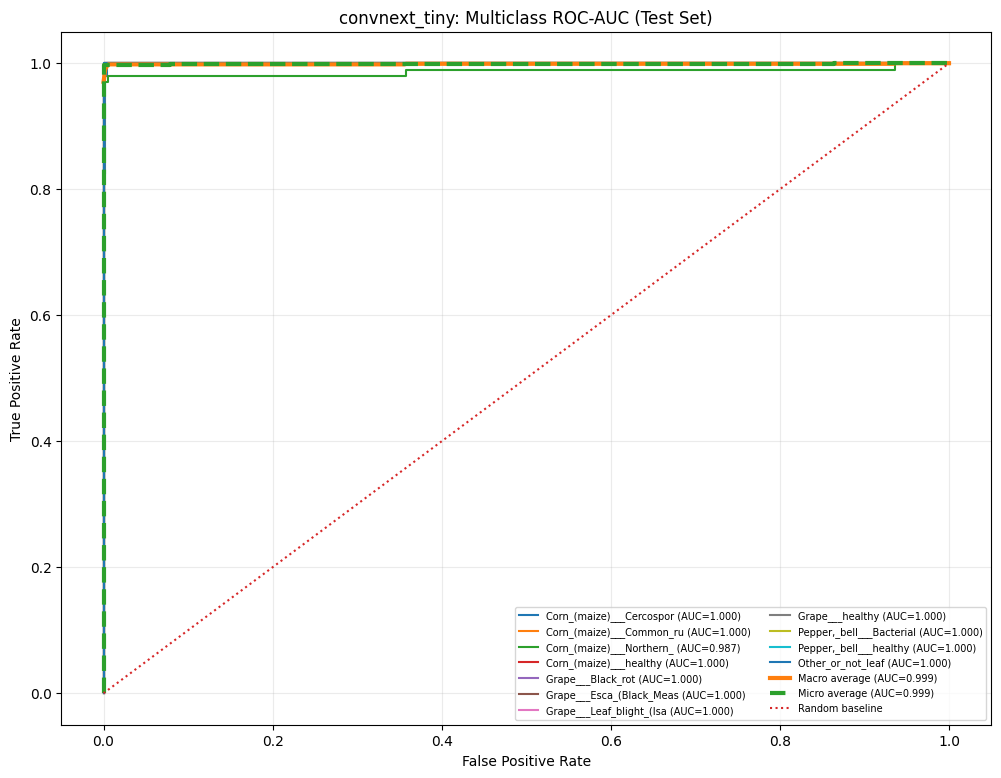

Saved: /content/drive/MyDrive/plant-disease-v2/results/convnext_tiny_roc_auc_multiclass_test.png


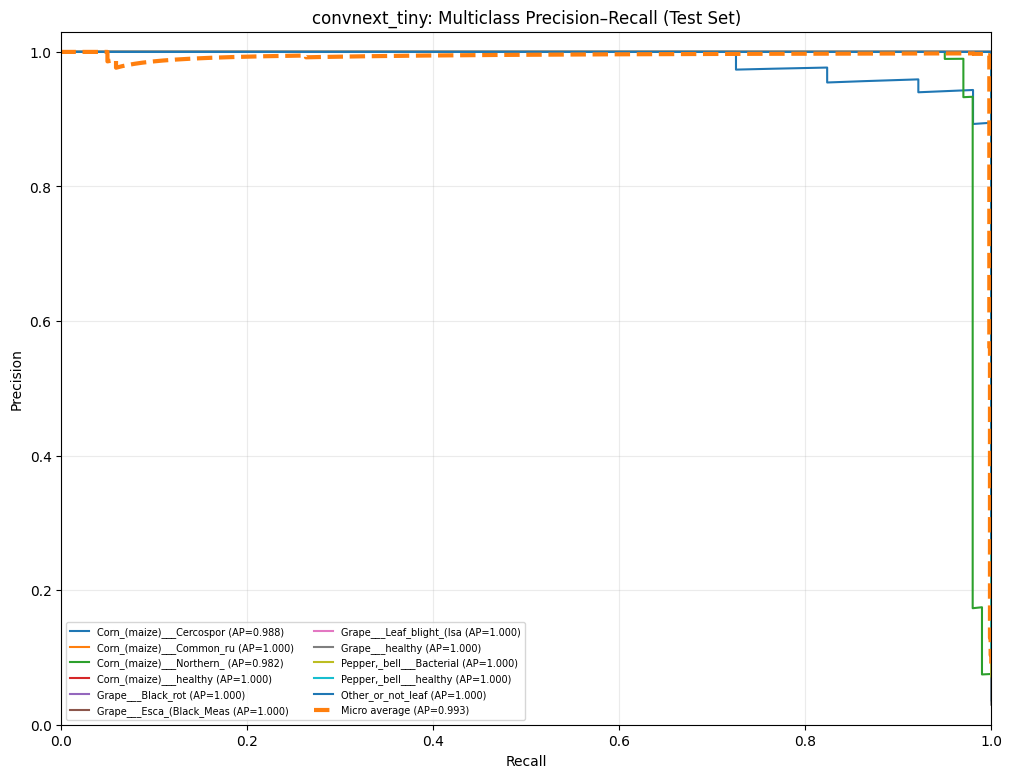

Saved: /content/drive/MyDrive/plant-disease-v2/results/convnext_tiny_precision_recall_ap_test.png


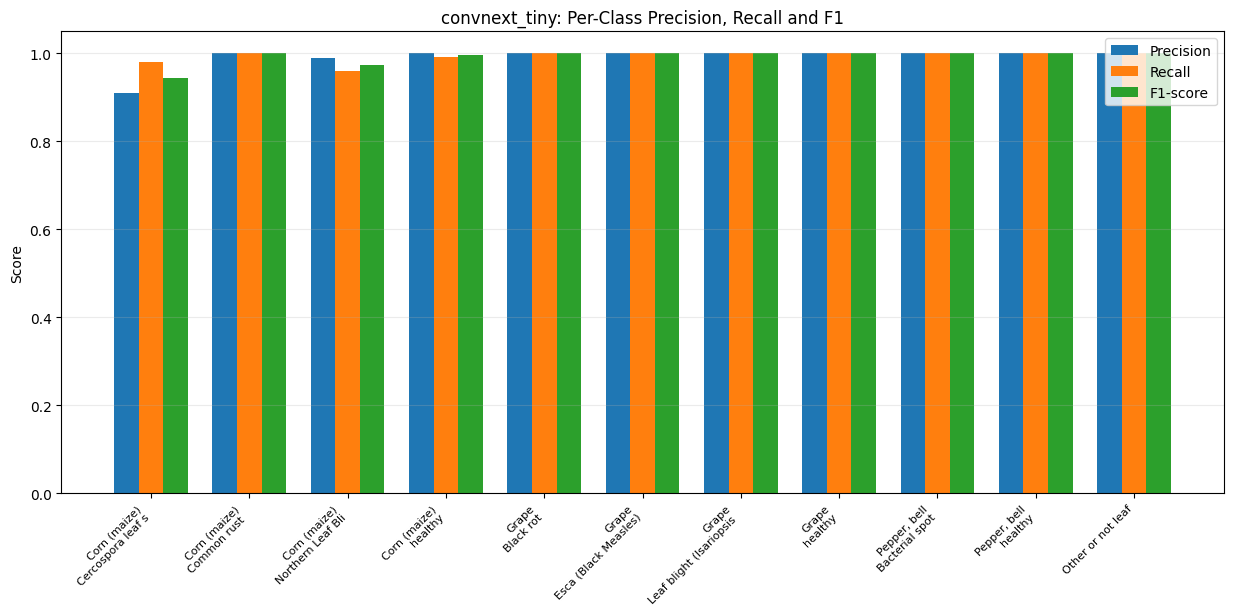

Saved: /content/drive/MyDrive/plant-disease-v2/results/convnext_tiny_precision_recall_f1_test.png

========== EXTRA TEST METRICS ==========
Model: convnext_tiny
Macro ROC-AUC (OvR): 0.9988
Micro ROC-AUC:       0.9987
Macro Average Precision: 0.9972
Micro Average Precision: 0.9934
Macro F1: 0.9921
CSV saved: /content/drive/MyDrive/plant-disease-v2/results/convnext_tiny_extra_metrics_test.csv
All extra evaluation plots saved successfully.


In [33]:

# ============================================================
# EXTRA REPORT PLOTS: MULTICLASS ROC-AUC, PR-AP, PRECISION,
# RECALL, F1 + CSV
# Saves to the existing Drive results folder using SHORT prefix.
# Run AFTER model evaluation, while the Colab session is active.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.special import softmax as scipy_softmax
from sklearn.metrics import (
    roc_curve, auc, roc_auc_score,
    precision_recall_curve, average_precision_score,
    precision_recall_fscore_support
)
from sklearn.preprocessing import label_binarize

# Use the same folder and model naming convention as your notebook.
RES_DIR = Path(RES_DIR)
RES_DIR.mkdir(parents=True, exist_ok=True)

# Uses existing variables from the completed training/evaluation:
# SHORT, CLASS_NAMES, lg_te, y_te
assert "lg_te" in globals() and "y_te" in globals(), (
    "Test logits/labels not found. Run the model evaluation cell first."
)
assert len(CLASS_NAMES) == 11, "Expected the 11-class dataset."

model_name = str(SHORT)
class_names = list(CLASS_NAMES)
n_classes = len(class_names)
labels = np.arange(n_classes)

logits = np.asarray(lg_te)
y_true = np.asarray(y_te).astype(int).ravel()

assert logits.ndim == 2 and logits.shape[1] == n_classes
assert len(logits) == len(y_true)
assert set(np.unique(y_true)).issubset(set(labels))

# Convert logits into class probabilities.
# ROC-AUC and AP are computed on the in-domain test set.
probs = scipy_softmax(logits, axis=1)
y_bin = label_binarize(y_true, classes=labels)

# Defensive check: every class must have positive and negative test examples.
class_counts = np.bincount(y_true, minlength=n_classes)
assert np.all(class_counts > 0), (
    "Some classes are absent from test: "
    + str([class_names[i] for i in np.where(class_counts == 0)[0]])
)

def save_plot(fig, filename):
    path = RES_DIR / f"{model_name}_{filename}.png"
    fig.savefig(path, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("Saved:", path)

# ------------------------------------------------------------
# 1. MULTICLASS ROC CURVES: ONE-VS-REST
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 9))
all_fpr = np.linspace(0, 1, 501)
tprs = []

for i, name in enumerate(class_names):
    fpr, tpr, _ = roc_curve(y_bin[:, i], probs[:, i])
    class_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, linewidth=1.5,
            label=f"{name[:24]} (AUC={class_auc:.3f})")
    tprs.append(np.interp(all_fpr, fpr, tpr))

# Macro-average curve
mean_tpr = np.mean(tprs, axis=0)
macro_auc_curve = auc(all_fpr, mean_tpr)

# Micro-average curve
fpr_micro, tpr_micro, _ = roc_curve(y_bin.ravel(), probs.ravel())
micro_auc = auc(fpr_micro, tpr_micro)

ax.plot(all_fpr, mean_tpr, linewidth=3,
        label=f"Macro average (AUC={macro_auc_curve:.3f})")
ax.plot(fpr_micro, tpr_micro, linewidth=3, linestyle="--",
        label=f"Micro average (AUC={micro_auc:.3f})")
ax.plot([0, 1], [0, 1], linestyle=":", linewidth=1.5,
        label="Random baseline")

ax.set(
    xlabel="False Positive Rate",
    ylabel="True Positive Rate",
    title=f"{model_name}: Multiclass ROC-AUC (Test Set)"
)
ax.grid(alpha=0.25)
ax.legend(loc="lower right", fontsize=7, ncol=2)
save_plot(fig, "roc_auc_multiclass_test")

# ------------------------------------------------------------
# 2. PRECISION-RECALL CURVES + AVERAGE PRECISION
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 9))
aps = []

for i, name in enumerate(class_names):
    precision, recall, _ = precision_recall_curve(
        y_bin[:, i], probs[:, i]
    )
    ap = average_precision_score(y_bin[:, i], probs[:, i])
    aps.append(ap)
    ax.plot(recall, precision, linewidth=1.5,
            label=f"{name[:24]} (AP={ap:.3f})")

micro_ap = average_precision_score(y_bin, probs, average="micro")
macro_ap = average_precision_score(y_bin, probs, average="macro")

# Micro-average PR curve
p_micro, r_micro, _ = precision_recall_curve(
    y_bin.ravel(), probs.ravel()
)
ax.plot(r_micro, p_micro, linewidth=3, linestyle="--",
        label=f"Micro average (AP={micro_ap:.3f})")

ax.set(
    xlabel="Recall",
    ylabel="Precision",
    title=f"{model_name}: Multiclass Precision–Recall (Test Set)"
)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.03)
ax.grid(alpha=0.25)
ax.legend(loc="lower left", fontsize=7, ncol=2)
save_plot(fig, "precision_recall_ap_test")

# ------------------------------------------------------------
# 3. GROUPED PRECISION, RECALL AND F1 BAR CHART
# ------------------------------------------------------------
y_pred = probs.argmax(axis=1)
precision, recall, f1, support = precision_recall_fscore_support(
    y_true, y_pred, labels=labels, zero_division=0
)

x = np.arange(n_classes)
width = 0.25

fig, ax = plt.subplots(figsize=(15, 6))
ax.bar(x - width, precision, width, label="Precision")
ax.bar(x, recall, width, label="Recall")
ax.bar(x + width, f1, width, label="F1-score")

ax.set_xticks(x)
ax.set_xticklabels(
    [name.replace("___", "\n").replace("_", " ")[:30]
     for name in class_names],
    rotation=45, ha="right", fontsize=8
)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title(f"{model_name}: Per-Class Precision, Recall and F1")
ax.legend()
ax.grid(axis="y", alpha=0.25)
save_plot(fig, "precision_recall_f1_test")

# ------------------------------------------------------------
# 4. SAVE PER-CLASS METRICS + MACRO/MICRO SUMMARY TO CSV
# ------------------------------------------------------------
class_auc_values = [
    roc_auc_score(y_bin[:, i], probs[:, i])
    for i in labels
]
class_ap_values = [
    average_precision_score(y_bin[:, i], probs[:, i])
    for i in labels
]

rows = []
for i, name in enumerate(class_names):
    rows.append({
        "class": name,
        "support": int(support[i]),
        "precision": float(precision[i]),
        "recall": float(recall[i]),
        "f1_score": float(f1[i]),
        "roc_auc_ovr": float(class_auc_values[i]),
        "average_precision": float(class_ap_values[i])
    })

rows.append({
    "class": "MACRO_AVERAGE",
    "support": int(len(y_true)),
    "precision": float(np.mean(precision)),
    "recall": float(np.mean(recall)),
    "f1_score": float(np.mean(f1)),
    "roc_auc_ovr": float(np.mean(class_auc_values)),
    "average_precision": float(macro_ap)
})

rows.append({
    "class": "MICRO_AVERAGE",
    "support": int(len(y_true)),
    "precision": float(precision_recall_fscore_support(
        y_true, y_pred, average="micro", zero_division=0
    )[0]),
    "recall": float(precision_recall_fscore_support(
        y_true, y_pred, average="micro", zero_division=0
    )[1]),
    "f1_score": float(precision_recall_fscore_support(
        y_true, y_pred, average="micro", zero_division=0
    )[2]),
    "roc_auc_ovr": float(micro_auc),
    "average_precision": float(micro_ap)
})

metrics_df = pd.DataFrame(rows)
csv_path = RES_DIR / f"{model_name}_extra_metrics_test.csv"
metrics_df.to_csv(csv_path, index=False)

print("\n========== EXTRA TEST METRICS ==========")
print("Model:", model_name)
print(f"Macro ROC-AUC (OvR): {np.mean(class_auc_values):.4f}")
print(f"Micro ROC-AUC:       {micro_auc:.4f}")
print(f"Macro Average Precision: {macro_ap:.4f}")
print(f"Micro Average Precision: {micro_ap:.4f}")
print(f"Macro F1: {np.mean(f1):.4f}")
print("CSV saved:", csv_path)
print("All extra evaluation plots saved successfully.")
